# Phase 1 - Baseline LSTM

Replicates Hilders et al.'s LSTM encoder head on AmsterdamUMCdb.

Ported from `SepsisPhenotyping/SGROUP/` (sgroup_model.py, icu_dataset.py, utils.py, train_sgroup.py).

## Imports

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

from sklearn.metrics import accuracy_score, roc_auc_score, mean_squared_error

pd.set_option('display.max_columns', None)


## Config


In [2]:
FEATURES_INCLUDED = [
    'ast', 'alt', 'bicarbonate', 'bilirubin', 'bun', 'calcium', 'chloride',
    'potassium', 'creatinine', 'glucose', 'heart_rate', 'hematocrit', 'hemoglobin',
    'lactate', 'spo2', 'pao2', 'paco2', 'ph', 'platelet', 'resp_rate',
    'sodium', 'sysbp', 'meanbp', 'diasbp', 'tempc', 'wbc', 'gcs_eye',
    'gcs_motor', 'admission_age_norm', 'weight_norm', 'height_norm',
    'weight_null', 'height_null', 'gender'
]

OUTCOMES_INCLUDED = [
    '90day_mortality',
    'LOS_remaining_days',
    'rrt_next_timestep',
    'mv_next_timestep'
]

OUTCOMES_MORTALITY_ONLY = ['90day_mortality'] # added to run only mortality if required

UNIQUE_STAY_ID = 'admissionid'

print(f'{len(FEATURES_INCLUDED)} input features')


34 input features


## Dataset

Unchanged from Hilders' `icu_dataset.py`

In [3]:
class ICUDataset(Dataset):
    def __init__(self, data, features, outcomes, unique_stay_id='admissionid'):
        self.data = data
        self.vo_ids = data[unique_stay_id].unique()
        self.features = features
        self.outcomes = outcomes
        self.unique_stay_id = unique_stay_id

    def __len__(self):
        return len(self.vo_ids)

    def __getitem__(self, idx):
        visit_id = self.vo_ids[idx]
        patient_data = self.data[self.data[self.unique_stay_id] == visit_id]
        sequence = patient_data[self.features].values
        labels = patient_data[self.outcomes].values

        return torch.tensor(sequence, dtype=torch.float32), torch.tensor(labels, dtype=torch.float32)


def custom_collate_fn(batch):
    """Sequences are variable-length, so return lists rather than stacking."""
    X, y = list(zip(*batch))
    return X, y


## Model

LSTM_Encoder and MLP_Predictor are unchanged from Hilders sgroup_model.py. SGROUP_network is also the same with just a few changes for adding the variable to switch prediction.   
ClaudeAI. prompt- Need the hilders code to be able to switch prediction between just mortality and all 4 outcomes. Can we add a variable to the class for the same?

In [4]:
class ExponentialActivation(nn.Module):
    """Element-wise exponential activation, used for non-negative outputs like LOS."""
    def forward(self, input):
        return torch.exp(input)


ACTIVATION_DICT = {
    'sigmoid': nn.Sigmoid(),
    'exp': ExponentialActivation()
}


class LSTM_Encoder(nn.Module):
    """Multi-layer LSTM that encodes variable-length ICU time-series into hidden states."""
    def __init__(self, input_dim, hidden_dim, num_layers=3, device='cpu'):
        super().__init__()
        self.device = device
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        ).to(self.device)

    def forward(self, input, input_padded=False):
        input_lens = list(map(len, input))
        if not input_padded:
            input = pad_sequence(input, batch_first=True)

        input_packed = pack_padded_sequence(input, input_lens, batch_first=True, enforce_sorted=False).to(self.device)
        encoded, (ht, ct) = self.lstm(input_packed)
        output, output_lens = pad_packed_sequence(encoded, batch_first=True)

        return encoded, output, output_lens


class MLP_Predictor(nn.Module):
    """Two-layer MLP head that maps encoder hidden states to a single outcome."""
    def __init__(self, encoder_dim, output_dim, output_activation=None, device='cpu'):
        super().__init__()
        self.device = device
        intermediate_dim = encoder_dim // 2

        layers = [
            nn.Linear(encoder_dim, intermediate_dim),
            nn.BatchNorm1d(intermediate_dim),
            nn.ReLU(),
            nn.Linear(intermediate_dim, output_dim)
        ]
        if output_activation is not None:
            layers.append(ACTIVATION_DICT[output_activation])

        self.network = nn.Sequential(*layers).to(self.device)

    def forward(self, input):
        input = input.to(self.device)
        batch_size, seq_len, feature_dim = input.shape
        input = input.view(-1, feature_dim)

        output = self.network(input)
        output = output.view(batch_size, seq_len, -1)

        return output


In [5]:
class SGROUP_Network(nn.Module):
    """Shared LSTM encoder with outcome-specific prediction heads.

    outcomes: list of keys from ALL_CRITERIA to train on. Order must match
    the column order of the labels tensor produced by ICUDataset.
    """

    ALL_CRITERIA = {
        'mortality': {
            'criterion': nn.BCEWithLogitsLoss(reduction='none'),
            'weight': 1.0, 'is_binary': True, 'output_config': (1, None)
        },
        'LOS': {
            'criterion': nn.MSELoss(reduction='none'),
            'weight': 0.001, 'is_binary': False, 'output_config': (1, 'exp')
        },
        'rrt': {
            'criterion': nn.BCEWithLogitsLoss(reduction='none'),
            'weight': 0.25, 'is_binary': True, 'output_config': (1, None)
        },
        'mv': {
            'criterion': nn.BCEWithLogitsLoss(reduction='none'),
            'weight': 0.25, 'is_binary': True, 'output_config': (1, None)
        }
    }

    def __init__(self, input_dim, hidden_dim, outcomes=['mortality'],
                 encoder_class=LSTM_Encoder, predictor_class=MLP_Predictor,
                 num_encoder_layers=3, device='cpu'):
        super().__init__()
        self.device = device
        self.outcomes = outcomes
        self.encoder = encoder_class(input_dim, hidden_dim, num_layers=num_encoder_layers, device=self.device)

        self.criteria = {key: self.ALL_CRITERIA[key] for key in outcomes}

        self.predictors = nn.ModuleList([
            predictor_class(
                hidden_dim,
                self.criteria[key]['output_config'][0],
                output_activation=self.criteria[key]['output_config'][1],
                device=self.device
            )
            for key in outcomes
        ])

    def forward(self, input):
        encoding, output, output_lens = self.encoder(input)
        predictions = [predictor(output) for predictor in self.predictors]
        return encoding, output, output_lens, predictions

    def compute_loss(self, preds, labels, lengths):
        losses = {key: [] for key in self.criteria.keys()}

        for i, length in enumerate(lengths):
            for j, (key, value) in enumerate(self.criteria.items()):
                criterion = value['criterion']
                weight = value['weight']
                pred = preds[j][i][:length].squeeze(-1)
                label = labels[i][:length, j].float().to(self.device)

                loss = criterion(pred, label).mean()
                losses[key].append(loss * weight)

        mean_weighted_losses = [torch.mean(torch.stack(loss_list)) for loss_list in losses.values()]
        return torch.mean(torch.stack(mean_weighted_losses))

    def initialise_result_dict(self):
        results = {}
        for key, value in self.criteria.items():
            if value['is_binary']:
                results[key] = {'accuracy': [], 'labels': [], 'preds': []}
            else:
                results[key] = {'mse': []}
        return results

    def compile_results(self, results):
        compiled_results = {}
        for key, value in self.criteria.items():
            metrics = results[key]
            if value['is_binary']:
                compiled_results[f'{key}_acc'] = np.mean(metrics['accuracy'])
                if len(np.unique(metrics['labels'])) > 1:
                    mean_auroc = roc_auc_score(metrics['labels'], metrics['preds'])
                else:
                    mean_auroc = float('nan')
                compiled_results[f'{key}_auroc'] = np.mean(mean_auroc)
            else:
                compiled_results[f'{key}_mse'] = np.mean(metrics['mse'])
        return compiled_results

    def compute_metrics(self, preds, labels, lengths):
        results = self.initialise_result_dict()

        for i, length in enumerate(lengths):
            for j, (key, value) in enumerate(self.criteria.items()):
                valid_preds = preds[j][i][:length].squeeze(-1)
                valid_labels = labels[i][:length, j].float()

                if value['is_binary']:
                    pred_probs = torch.sigmoid(valid_preds)
                    pred_binary = (pred_probs > 0.5).float().cpu().detach().numpy().flatten()
                    labels_binary = valid_labels.cpu().numpy().flatten()

                    results[key]['accuracy'].append(accuracy_score(labels_binary, pred_binary))
                    results[key]['preds'].extend(pred_probs.cpu().detach().numpy().flatten())
                    results[key]['labels'].extend(labels_binary)
                else:
                    mse_value = mean_squared_error(valid_labels.cpu().numpy(), valid_preds.cpu().detach().numpy())
                    results[key]['mse'].append(mse_value)

        return self.compile_results(results)


## Load pre-split data


In [ ]:
DATA_DIR = '../data/splits'

train_data = pd.read_csv(f'{DATA_DIR}/train.csv')
val_data = pd.read_csv(f'{DATA_DIR}/val.csv')
test_data = pd.read_csv(f'{DATA_DIR}/test.csv')

print(f'Train: {train_data.shape}, {train_data.admissionid.nunique()} admissions')
print(f'Val:   {val_data.shape}, {val_data.admissionid.nunique()} admissions')
print(f'Test:  {test_data.shape}, {test_data.admissionid.nunique()} admissions')

train_data.head()


## Build datasets & dataloaders
From Hilders et al. github- utils.py 

In [ ]:
BATCH_SIZE = 256

train_dataset = ICUDataset(train_data, FEATURES_INCLUDED, OUTCOMES_INCLUDED, unique_stay_id=UNIQUE_STAY_ID)
val_dataset = ICUDataset(val_data, FEATURES_INCLUDED, OUTCOMES_INCLUDED, unique_stay_id=UNIQUE_STAY_ID)
test_dataset = ICUDataset(test_data, FEATURES_INCLUDED, OUTCOMES_INCLUDED, unique_stay_id=UNIQUE_STAY_ID)

train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=custom_collate_fn)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=custom_collate_fn)
test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=custom_collate_fn)

print(f'{len(train_dataset)} train / {len(val_dataset)} val / {len(test_dataset)} test patients')

# sanity check one batch
X_batch, y_batch = next(iter(train_dataloader))
print(f'Batch of {len(X_batch)} sequences, e.g. shapes {X_batch[0].shape}, {y_batch[0].shape}')


## Training utilities

From Hilders et al. github-  utils.py

In [8]:
def set_seeds(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)


def run_epoch(model, dataloader, device, optimizer=None):
    """Trains if optimizer is given, otherwise evaluates with no_grad."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    epoch_losses = []
    epoch_metrics = []

    desc = 'Training' if is_train else 'Validation'
    grad_context = torch.enable_grad() if is_train else torch.no_grad()

    with grad_context:
        with tqdm(total=len(dataloader), desc=desc, unit='batch') as pbar:
            for X, y in dataloader:
                if is_train:
                    optimizer.zero_grad()

                encoding, output, output_lens, predictions = model(X)
                loss = model.compute_loss(predictions, y, output_lens)

                if is_train:
                    loss.backward()
                    optimizer.step()

                metrics = model.compute_metrics(predictions, y, output_lens)
                epoch_losses.append(loss.item())
                epoch_metrics.append(metrics)

                pbar.set_postfix(loss=loss.item(), **metrics)
                pbar.update()

    avg_loss = float(np.mean(epoch_losses))
    avg_metrics = {k: float(np.nanmean([m[k] for m in epoch_metrics])) for k in epoch_metrics[0]}
    return avg_loss, avg_metrics


## Train the model

From Hilders et al. github- train_sgroup.py

In [ ]:
SEED = 42
EMBEDDING_SIZE = 32
LEARNING_RATE = 0.01
N_EPOCHS = 150
CHECKPOINT_INTERVAL = 10  # only keep every Nth epoch checkpoint on disk, to save space
SAVE_FOLDER = Path('model_checkpoints/full_baseline')
SAVE_FOLDER.mkdir(parents=True, exist_ok=True)

set_seeds(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

model = SGROUP_Network(
    input_dim=len(FEATURES_INCLUDED),
    hidden_dim=EMBEDDING_SIZE,
    outcomes=['mortality', 'LOS', 'rrt', 'mv'],
    device=device
).to(device)

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = []
best_val_auroc = -1.0
best_epoch = -1
best_path = SAVE_FOLDER / 'SGROUPmodel_mortality_best.pth'

for epoch in range(N_EPOCHS):
    train_loss, train_metrics = run_epoch(model, train_dataloader, device, optimizer)
    val_loss, val_metrics = run_epoch(model, val_dataloader, device)

    metrics_str = ' | '.join(f'{k}: {train_metrics[k]:.4f}/{val_metrics[k]:.4f}' for k in train_metrics)
    print(f'Epoch [{epoch + 1}/{N_EPOCHS}] Loss: {train_loss:.4f}/{val_loss:.4f} {metrics_str}')

    history.append({
        'epoch': epoch + 1, 'train_loss': train_loss, 'val_loss': val_loss,
        **{f'train_{k}': v for k, v in train_metrics.items()},
        **{f'val_{k}': v for k, v in val_metrics.items()}
    })

    if val_metrics['mortality_auroc'] > best_val_auroc:
        best_val_auroc = val_metrics['mortality_auroc']
        best_epoch = epoch + 1
        torch.save(model.state_dict(), best_path)

    if (epoch + 1) % CHECKPOINT_INTERVAL == 0:
        checkpoint_path = SAVE_FOLDER / f'SGROUPmodel_mortality_Epoch{epoch + 1}_of_{N_EPOCHS}.pth'
        torch.save(model.state_dict(), checkpoint_path)

final_path = SAVE_FOLDER / f'SGROUPmodel_mortality_Epochs{N_EPOCHS}_final.pth'
torch.save(model.state_dict(), final_path)
print(f'Saved final checkpoint to {final_path}')
print(f'Best val mortality_auroc: {best_val_auroc:.4f} at epoch {best_epoch}, saved to {best_path}')

history_df = pd.DataFrame(history)
history_df.to_csv(SAVE_FOLDER / 'training_history.csv', index=False)


## Training curve

ClaudeAI. Prompt- Give me the code for plotting mortality, los, mv and rrt 

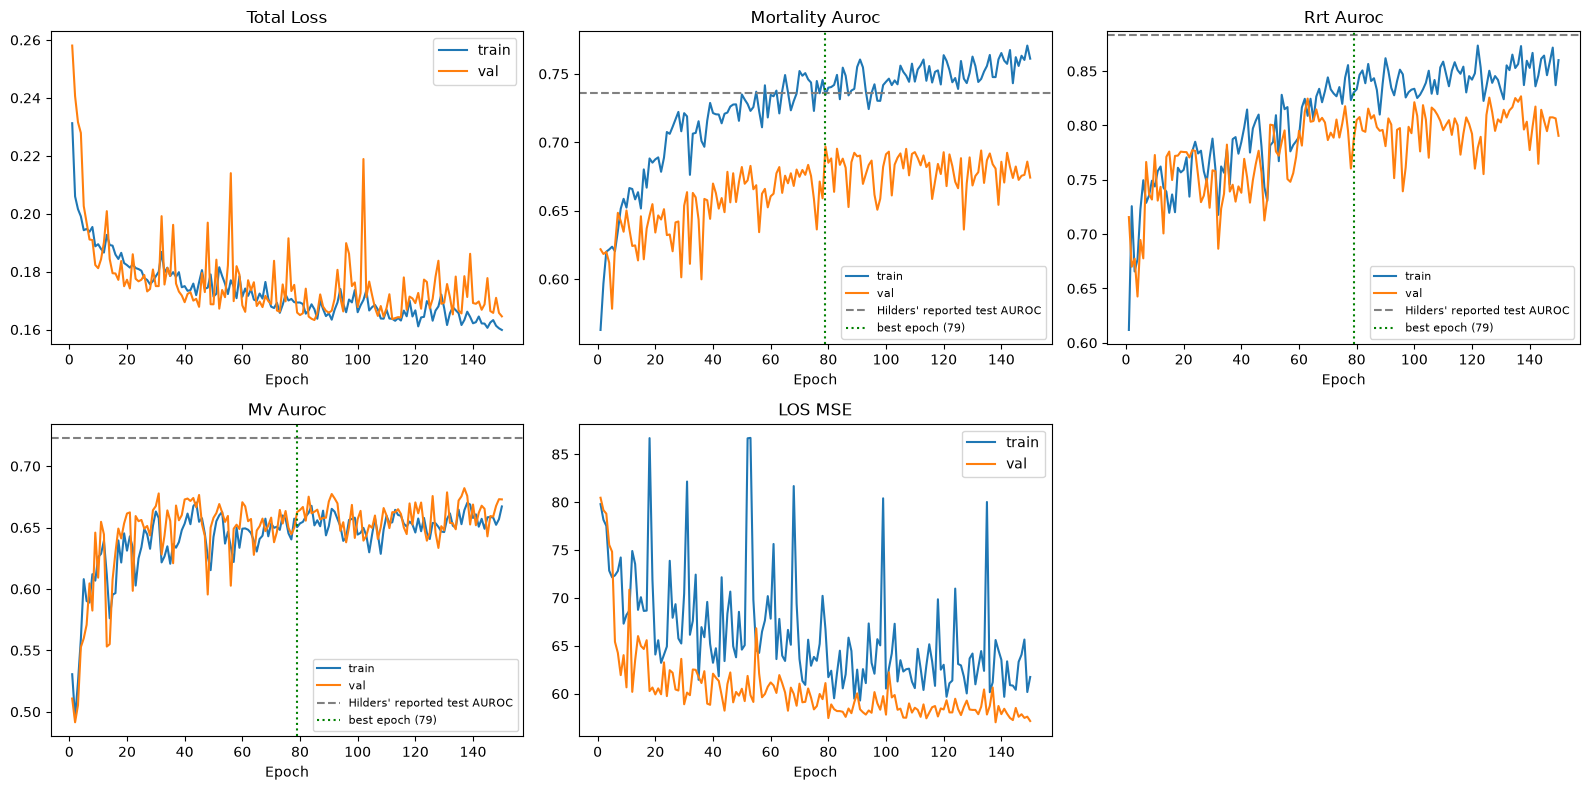

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

axes[0, 0].plot(history_df['epoch'], history_df['train_loss'], label='train')
axes[0, 0].plot(history_df['epoch'], history_df['val_loss'], label='val')
axes[0, 0].set_title('Total Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].legend()

auroc_panels = [
    ('mortality_auroc', axes[0, 1], 0.736),
    ('rrt_auroc', axes[0, 2], 0.883),
    ('mv_auroc', axes[1, 0], 0.723),
]
for key, ax, hilders_val in auroc_panels:
    ax.plot(history_df['epoch'], history_df[f'train_{key}'], label='train')
    ax.plot(history_df['epoch'], history_df[f'val_{key}'], label='val')
    ax.axhline(hilders_val, color='gray', linestyle='--', label="Hilders' reported test AUROC")
    ax.axvline(best_epoch, color='green', linestyle=':', label=f'best epoch ({best_epoch})')
    ax.set_title(key.replace('_', ' ').title())
    ax.set_xlabel('Epoch')
    ax.legend(fontsize=8)

axes[1, 1].plot(history_df['epoch'], history_df['train_LOS_mse'], label='train')
axes[1, 1].plot(history_df['epoch'], history_df['val_LOS_mse'], label='val')
axes[1, 1].set_title('LOS MSE')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].legend()

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

## Test set evaluation

Hilders et al.-  
mortality_acc:   0.667  
mortality_auroc: 0.736  
LOS_mse:         118.04  
rrt_acc:         0.861  
rrt_auroc:       0.883  
mv_acc:          0.710  
mv_auroc:        0.723  

In [11]:
model.load_state_dict(torch.load(best_path, weights_only=True, map_location=device))

test_loss, test_metrics = run_epoch(model, test_dataloader, device)

print(f'Best epoch: {best_epoch}, val mortality_auroc: {best_val_auroc:.4f}')
print(f'Test loss: {test_loss:.4f}')
for k, v in test_metrics.items():
    print(f'  {k}: {v:.4f}')


Validation:   0%|          | 0/2 [00:00<?, ?batch/s]

Best epoch: 79, val mortality_auroc: 0.6969
Test loss: 0.1713
  mortality_acc: 0.7597
  mortality_auroc: 0.7089
  LOS_mse: 65.2453
  rrt_acc: 0.9480
  rrt_auroc: 0.8228
  mv_acc: 0.9357
  mv_auroc: 0.6404
